In [1]:
import numpy as np
import pandas as pd
pd.set_option('display.max_rows', 100, 'display.max_columns', 200)
#строчка нужна, чтобы датасеты с множеством колонок отображались полностью
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# Линейная регрессия: эксперимент на искусственных данных

Сгенерируем искусственные данные. Каждый объект имеет один признак, который записан в переменную $X$. Целевая переменная $y$ зависит от $X$ по закону $y = 10X - 7$. Поскольку восстанавливать в точности линейную зависимость не интересно, к целевой переменной добавлен шум, имеющий нормальное распределение. Ниже визуализировано распределение шума.

(array([2., 1., 2., 1., 5., 1., 3., 3., 0., 2.]),
 array([-19.13280245, -15.64030939, -12.14781633,  -8.65532327,
         -5.16283021,  -1.67033715,   1.82215591,   5.31464897,
          8.80714203,  12.29963509,  15.79212816]),
 <BarContainer object of 10 artists>)

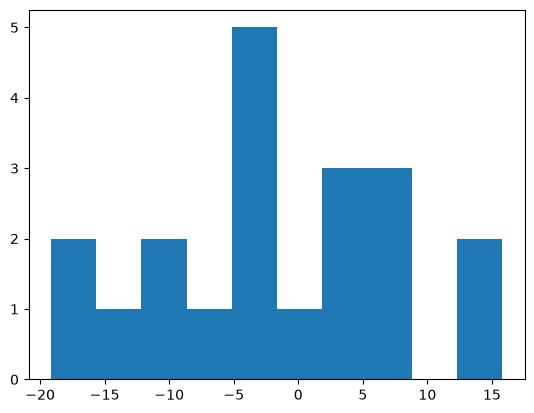

In [2]:
np.random.seed(42)
noise = np.random.randn(20) * 10
plt.hist(noise)

In [3]:
X = np.linspace(-5, 5, 20)
y = 10 * X - 7 + noise

X = X.reshape(-1,1) 
# Изменение формы необходимо, поскольку на вход линейной регрессии 
# должна подаваться двумерная матрица, а не вектор
X.shape

(20, 1)

### Задание 1 (0 баллов)
Разбейте данные на train и test в соотношении 1:1. Используйте функцию ``sklearn.model_selection.train_test_split``.

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

Визуализируем данные, используя библиотеку matplotlib.

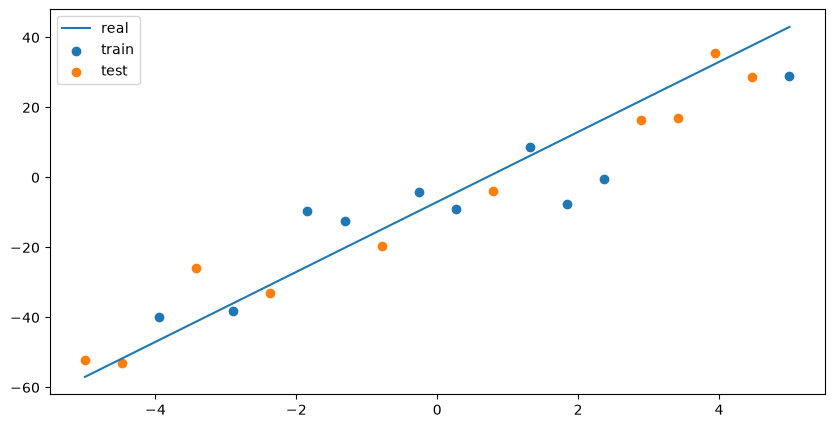

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(X, 10 * X - 7, label='real')
plt.scatter(X_train, y_train, label='train')
plt.scatter(X_test, y_test, label='test')
plt.legend()
plt.show()

### Задание 2 (2 балла)
Обучите модель линейной регрессии на тренировочной выборке и предскажите значения на тестовой.
Предсказанные ответы сохраните в переменную ``predictions``, а веса модели (угол наклона прямой и свободный член) --- в переменные ``w``, ``b``. О том, где внутри модели сохраняются веса, можно прочесть в <a href=https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html>документации</a>.

In [7]:
from sklearn.linear_model import LinearRegression

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

w = model.coef_[0]
b = model.intercept_

In [9]:
w, b

(np.float64(6.871783732626508), np.float64(-8.804571486688218))

Визуализируем предсказания.

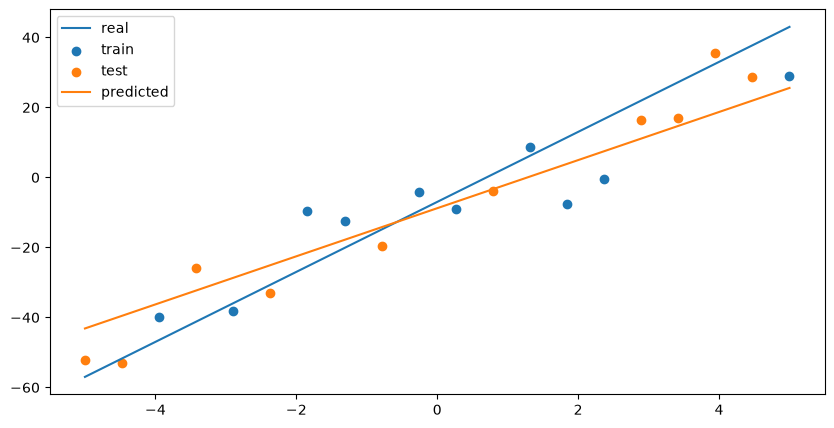

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(X, 10 * X - 7, label='real')
plt.scatter(X_train, y_train, label='train')
plt.scatter(X_test, y_test, label='test')
plt.plot(X, X * w + b, label='predicted')
plt.legend()
plt.show()

### Задание 3 (1 балл)
Вычислите среднеквадратичную и среднюю абсолютную ошибку на обучающем и тестовом множествах.

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

y_train_predicted = model.predict(X_train)
y_test_predicted = model.predict(X_test)

print('Train MSE: ', mean_squared_error(y_train, y_train_predicted))
print('Test MSE: ', mean_squared_error(y_test, y_test_predicted))

Train MSE:  60.13722305414702
Test MSE:  77.23543221685657


In [12]:
print('Train MAE: ', mean_absolute_error(y_train, y_train_predicted))
print('Test MAE: ', mean_absolute_error(y_test, y_test_predicted))

Train MAE:  7.053376379490045
Test MAE:  7.409316011912276


### Задание 4 (1 балл)
Сделайте выводы. Верно ли, что ошибка на train меньше, чем на test? В связи с чем это происходит?

Да, ошибка на train получилась меньше, чем на test: MSE 60.1 против 77.2, MAE 7.05 против 7.41. Это ожидаемо: веса модели подбираются так, чтобы минимизировать ошибку именно на обучающих объектах, поэтому на них она в среднем работает лучше, чем на новых данных, которых не видела. Тестовые точки содержат свою долю случайного шума, под который модель не подстраивалась.

Разница при этом небольшая, потому что модель простая (всего два параметра) и зависимость действительно линейная, так что сильного переобучения нет. Выборка очень маленькая (по 10 точек), поэтому результат зависит от случайного шума и разбиения, и в отдельных запусках ошибка на test может оказаться даже меньше, чем на train. По той же причине найденный наклон (≈ 6.9) заметно отличается от истинного значения 10.